# Manufacturing (VisA pcb1): EDA

**Phase:** Phase 1

**Purpose:** Understand the raw data before building anything on it, and collect material for edge cases and failure analysis.

**Inputs:** Raw dataset (not stored in the repo).

**Outputs:** Figures saved to results/figures/, notes added to docs/dataset-research.md.

## Steps

- [ ] Class balance and counts
- [ ] Image sizes and aspect ratios
- [ ] Duplicates or near duplicates (leakage check)
- [ ] Visual sample grid per class
- [ ] Defect area fraction (how tiny are the defects?)
- [ ] Check boxes derived from masks sit on the defects
- [ ] Pick edge cases: smallest defects, multiple defects, defects near the border

In [1]:
import json
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from vision_benchmark.utils import show_sample_images

In [2]:
# the notebook runs from notebooks/manufacturing/, so the repo root is two levels up
ROOT = os.path.join(os.getcwd(), "..", "..")
BENCH = os.path.join(ROOT, "bench")

df = pd.read_csv(os.path.join(BENCH, "split.csv"))
print(df.shape)

(1104, 10)


In [3]:
df.head()

,image_id,split,label,path,src_path,width,height,n_boxes,boxes,defect_area_frac
0,pcb1_defect_024,test,1,yolo\images\test\pcb1_defect_024.jpg,datasets\manufacturing_visa\pcb1\Data\Images\A...,1024,780,1,"[[0.53564453125, 0.6730769230769231, 0.0830078...",0.001655
1,pcb1_defect_091,test,1,yolo\images\test\pcb1_defect_091.jpg,datasets\manufacturing_visa\pcb1\Data\Images\A...,1024,780,1,"[[0.23193359375, 0.6583333333333333, 0.2177734...",0.003627
2,pcb1_defect_078,test,1,yolo\images\test\pcb1_defect_078.jpg,datasets\manufacturing_visa\pcb1\Data\Images\A...,1024,780,1,"[[0.27099609375, 0.3282051282051282, 0.0537109...",0.001080
3,pcb1_defect_077,test,1,yolo\images\test\pcb1_defect_077.jpg,datasets\manufacturing_visa\pcb1\Data\Images\A...,1024,780,1,"[[0.69970703125, 0.5743589743589743, 0.1748046...",0.005149
4,pcb1_defect_061,test,1,yolo\images\test\pcb1_defect_061.jpg,datasets\manufacturing_visa\pcb1\Data\Images\A...,1024,780,1,"[[0.4013671875, 0.34807692307692306, 0.0429687...",0.001079


In [4]:
df.tail()

,image_id,split,label,path,src_path,width,height,n_boxes,boxes,defect_area_frac
1099,pcb1_normal_0281,unused,0,NaN,datasets\manufacturing_visa\pcb1\Data\Images\N...,0,0,0,[],0.0
1100,pcb1_normal_0759,unused,0,NaN,datasets\manufacturing_visa\pcb1\Data\Images\N...,0,0,0,[],0.0
1101,pcb1_normal_0025,unused,0,NaN,datasets\manufacturing_visa\pcb1\Data\Images\N...,0,0,0,[],0.0
1102,pcb1_normal_0114,unused,0,NaN,datasets\manufacturing_visa\pcb1\Data\Images\N...,0,0,0,[],0.0
1103,pcb1_normal_0654,unused,0,NaN,datasets\manufacturing_visa\pcb1\Data\Images\N...,0,0,0,[],0.0


In [5]:
print(df['split'].value_counts().sum())
df['split'].value_counts()

1104


split
unused    454
test      330
train     200
val       120
Name: count, dtype: int64

In [6]:
df['label'].value_counts()

label
0    1004
1     100
Name: count, dtype: int64

In [7]:
# "unused" images were not resized or copied (width/height = 0, path empty), so keep only train/val/test
used = df[df["split"] != "unused"].reset_index(drop=True)
print(used.shape)

(650, 10)


In [8]:
used[["width", "height", "n_boxes", "defect_area_frac"]].describe()

,width,height,n_boxes,defect_area_frac
count,650.0,650.0,650.00000,650.000000
mean,1024.0,780.0,0.26000,0.001432
std,0.0,0.0,0.74794,0.009271
min,1024.0,780.0,0.00000,0.000000
25%,1024.0,780.0,0.00000,0.000000
50%,1024.0,780.0,0.00000,0.000000
75%,1024.0,780.0,0.00000,0.000000
max,1024.0,780.0,6.00000,0.127254


In [9]:
used_defect = used[used["label"] == 1].reset_index(drop=True)
print(used_defect.shape)

(100, 10)


In [10]:
used_defect[["width", "height", "n_boxes", "defect_area_frac"]].describe()

,width,height,n_boxes,defect_area_frac
count,100.0,100.0,100.000000,100.000000
mean,1024.0,780.0,1.690000,0.009310
std,0.0,0.0,1.107322,0.022120
min,1024.0,780.0,1.000000,0.000776
25%,1024.0,780.0,1.000000,0.001521
50%,1024.0,780.0,1.000000,0.001981
75%,1024.0,780.0,2.000000,0.003096
max,1024.0,780.0,6.000000,0.127254


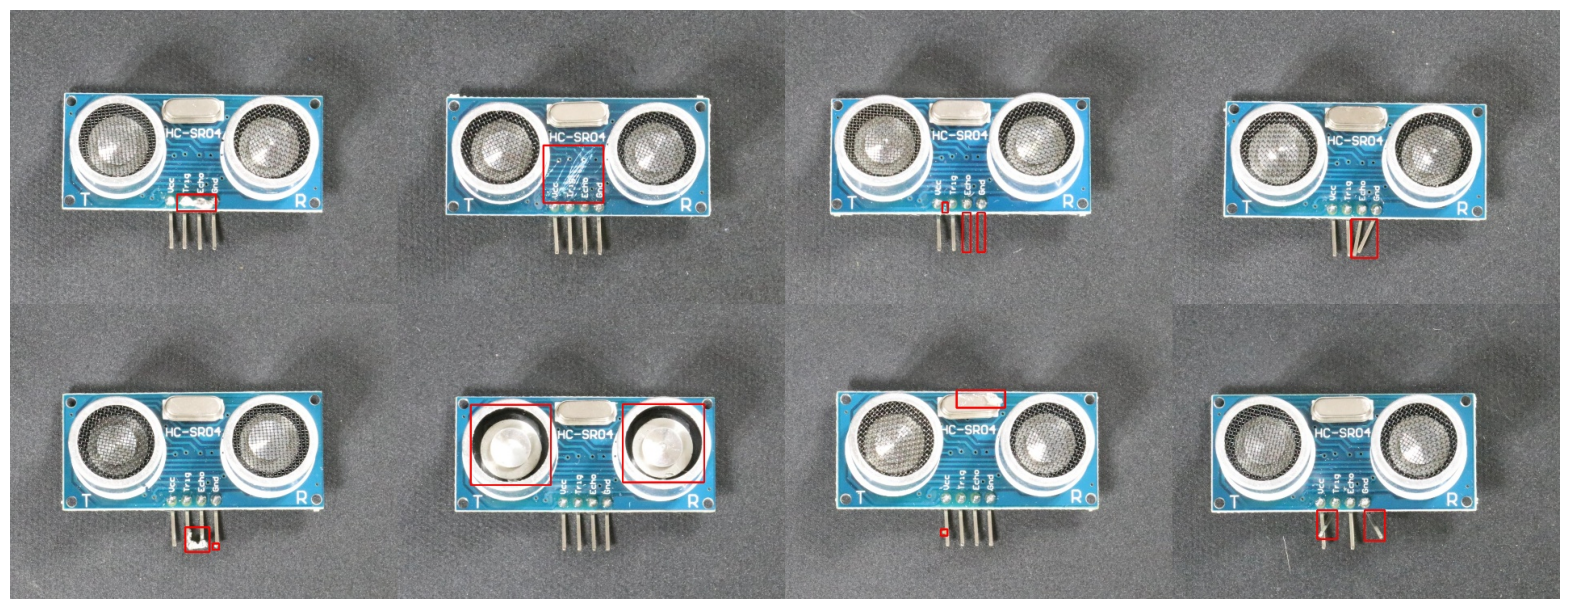

In [11]:
# preview.jpg was written by prepare_data.py: 8 defect images with their boxes
preview = cv2.cvtColor(cv2.imread(os.path.join(BENCH, "preview.jpg")), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(20, 8))
plt.imshow(preview)
plt.axis("off")
plt.show()

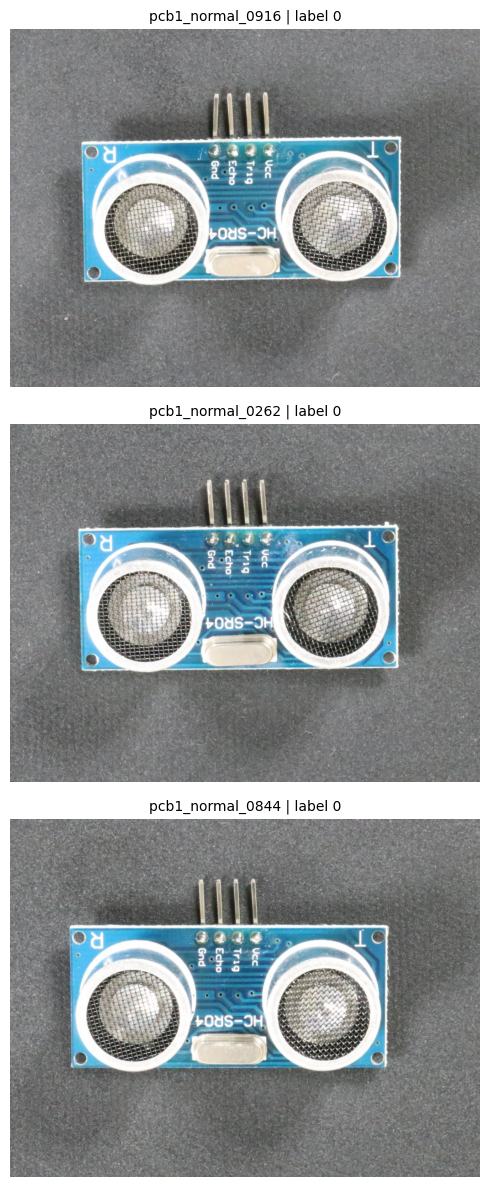

In [ ]:
show_sample_images(used, num_images=3, base_dir=BENCH)

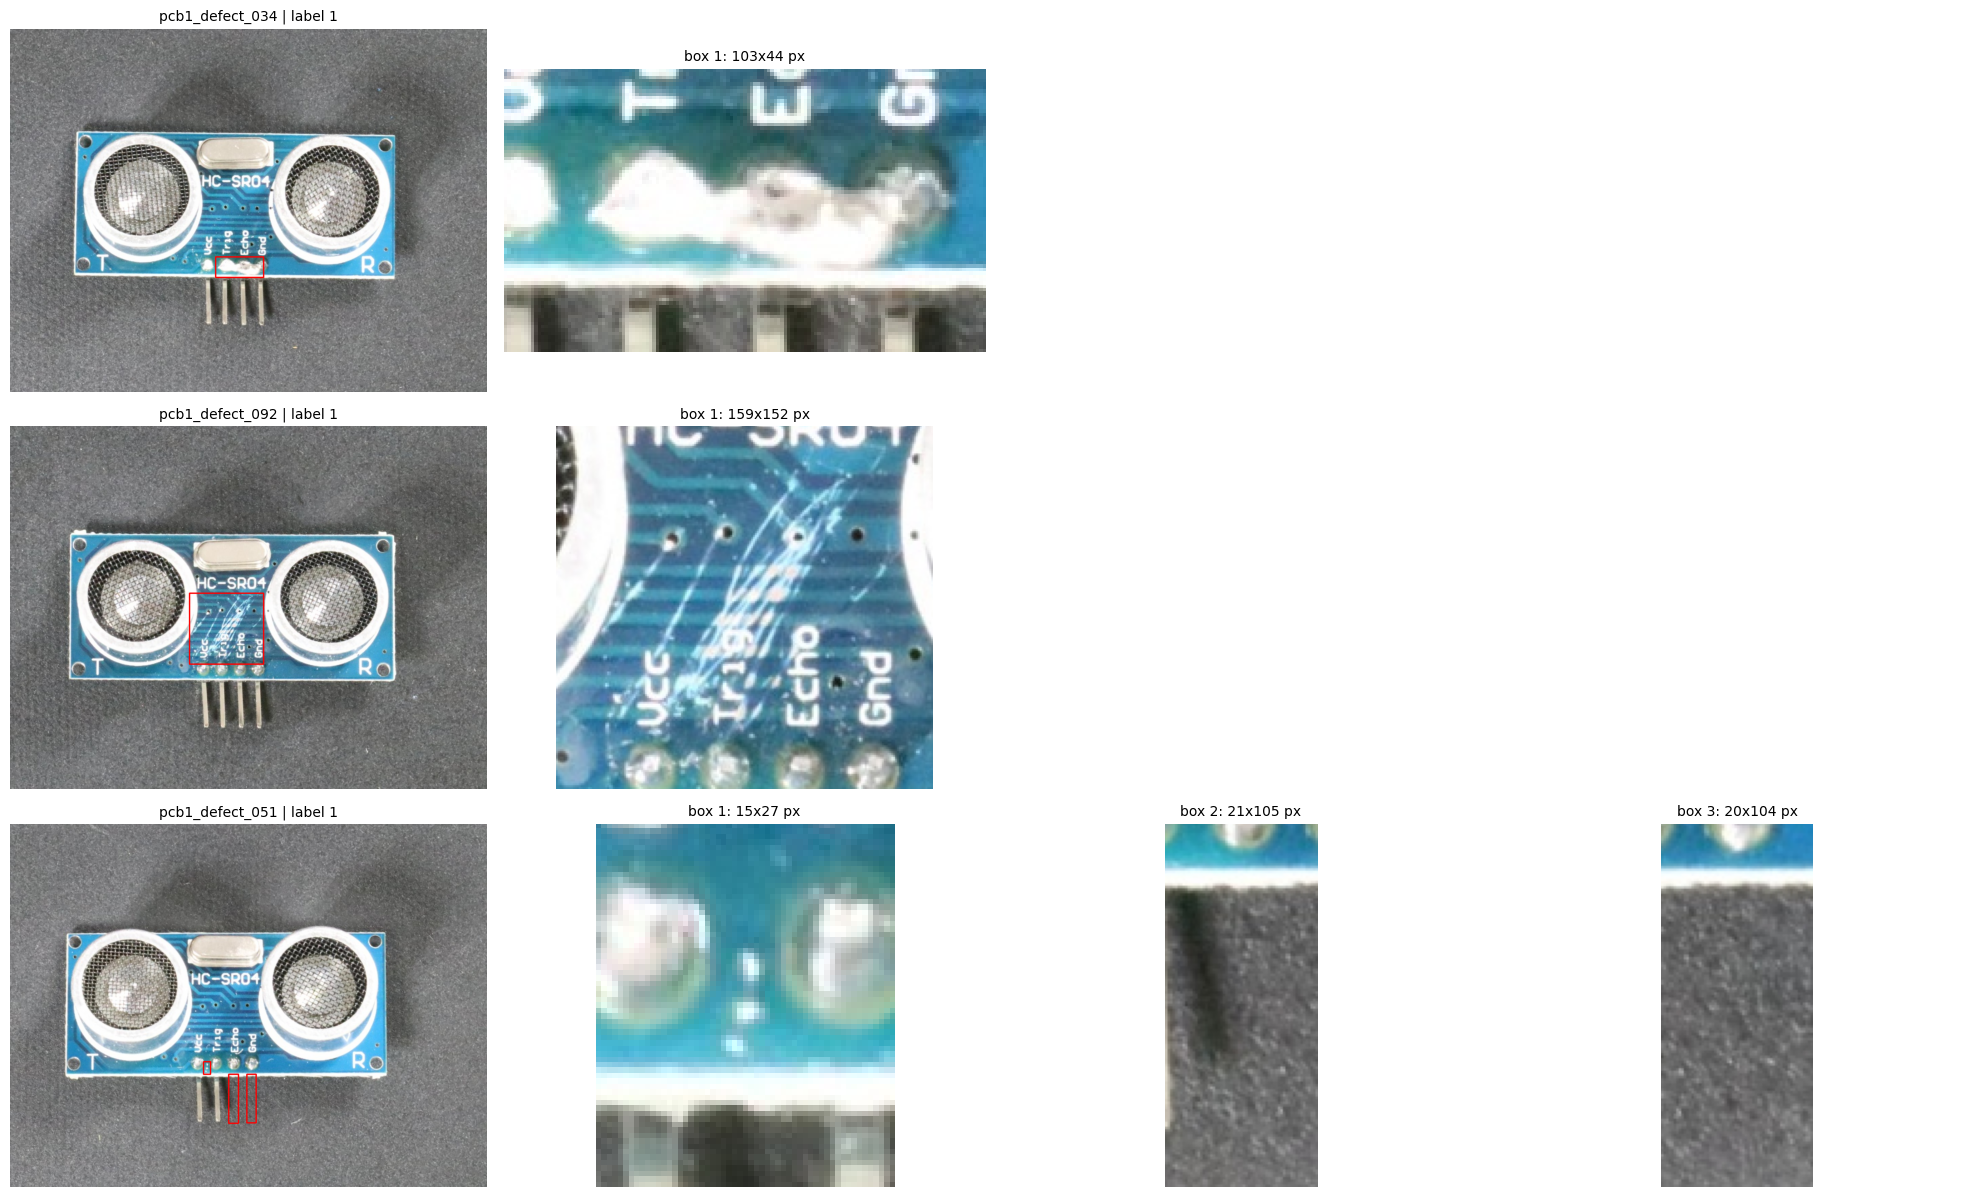

In [ ]:
show_sample_images(used, num_images=3, filter_data=["label", 1], crop_boxes=True, base_dir=BENCH)